# Example: Trichloroethylen detections in groundwaters on Long Island New York

adopted from Statistical Methods in Water Resources, book 4, Hydrologic Analysis and Interpretation, chapter 15, example 15.1

In [26]:
import numpy as np
import matplotlib.pyplot as plt # Visualization

plt.close('all') # close all open figures

## Step 1: explore the dataset

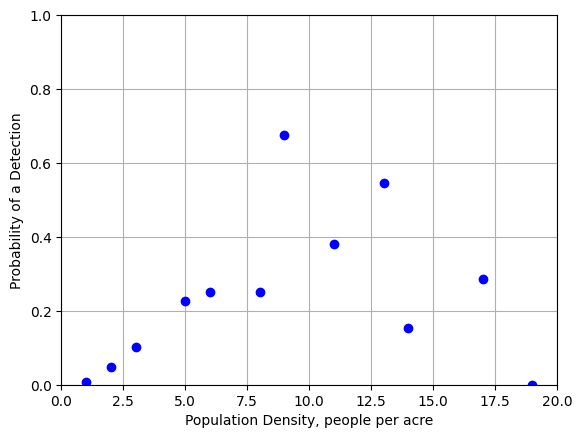

In [27]:
# create variable population density categories
popDensity = np.array([1,2,3,5,6,8,9,11,13,14,17,19]).reshape(-1,1)

# number of samples of TCE > 3 ppb
numDetect = np.array([1,4,10,25,11,8,29,19,6,2,2,0]).reshape(-1,1)

# number of samples
nSamples = np.array([149,84,98,111,44,32,43,50,11,13,7,1]).reshape(-1,1)

# get the probability of detection for each population density
probDetect = np.divide(numDetect,nSamples)

# plot probability of TCE > 3ppb vs. population density
plt.plot(popDensity, probDetect,  'ob')  # plot observations
plt.xlabel('Population Density, people per acre')
plt.ylabel('Probability of a Detection')
plt.ylim(0,1)
plt.xlim(0,20)
plt.grid(True)

## Step 2: create the dataset for the model

In [28]:
# create variable popDens
popDens = np.r_[np.ones(149),2*np.ones(84),3*np.ones(98),
                5*np.ones(111),6*np.ones(44),8*np.ones(32),
                9*np.ones(43),11*np.ones(50),13*np.ones(11),
                14*np.ones(13),17*np.ones(7),19*np.ones(1)].reshape(-1,1)

# create variable detect
detect = np.r_[np.ones(1), np.zeros(148), np.ones(4), np.zeros(80), np.ones(10), np.zeros(88),
               np.ones(25), np.zeros(86), np.ones(11), np.zeros(33), np.ones(8), np.zeros(24),
               np.ones(29), np.zeros(14), np.ones(19), np.zeros(31), np.ones(6), np.zeros(5),
               np.ones(2), np.zeros(11), np.ones(2), np.zeros(5), np.ones(0), np.zeros(1)].reshape(-1,1)

# check size of the data
print(popDens.shape)
print(detect.shape)

(643, 1)
(643, 1)


## Step 3: create the logistic regression model

- logistic regression has no closed form solution (analytical solution), need to use a 'solver'

- python has several solvers, we will use 'saga' : works well with large numbers, supports no penalty, l1,l2, and eleasticNet, support multinomial regression

- we also need to specify tolerance, when we want the solver to stop. Higher tolerance, faster convergence, but lower accuracy. Smaller tolerance, slower convergence, but better accuracy

In [29]:
# Import the model you want to use
from sklearn.linear_model import LogisticRegression

# Make an instance of the Model
lgrm = LogisticRegression(penalty=None, solver='saga', tol=0.00001, max_iter = 1000)

# Fit the model on the data, storing the information learned from the data
# .fit(x,y) x = popDens, y = detect

detect = detect.reshape(-1) # logisticRegression functions needs the y input to be flattened aray

lgrm.fit(popDens,detect)

LogisticRegression(max_iter=1000, penalty=None, solver='saga', tol=1e-05)

## Step 4: get model parameters

In [30]:
# show coefficients of the fitted model
print('---------------------')
print('intercept')
print(lgrm.intercept_)
print('beta coefficients')
print(lgrm.coef_)

---------------------
intercept
[-2.80078316]
beta coefficients
[[0.22557052]]


## Step 5: make predictions

In [31]:
# one new observation
x = np.array([5]).reshape(-1,1)
y_predict = lgrm.predict(x)
p_predict = lgrm.predict_proba(x)

print('---------------------')
print('predicted class')
print(y_predict)
print('predicted probability')
print(p_predict)

---------------------
predicted class
[0.]
predicted probability
[[0.84196615 0.15803385]]


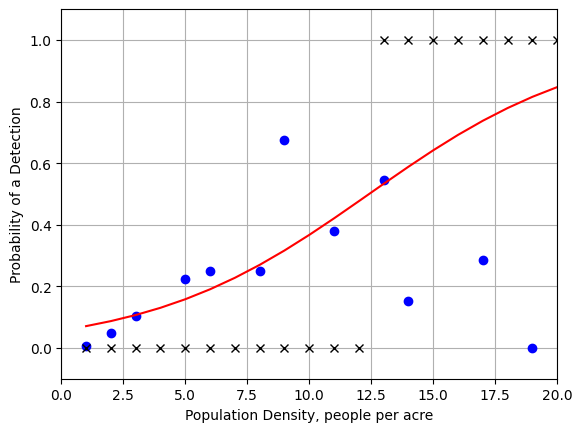

In [32]:
# Generate new predictions and plot results

# define new population density from 1 to 20
popDens_new = np.arange(1,21,1).reshape(-1,1)

# predict class 0,1
detect_predict_class = lgrm.predict(popDens_new)

# predict probability
detect_predict_prob = lgrm.predict_proba(popDens_new)

# plot data and prediction

plt.plot(popDensity, probDetect,  'ob')  # plot observations
plt.plot(popDens_new,detect_predict_prob[:,1],'r')
plt.plot(popDens_new,detect_predict_class,'kx')
plt.xlabel('Population Density, people per acre')
plt.ylabel('Probability of a Detection')
plt.ylim(-0.1,1.1)
plt.xlim(0,20)
plt.grid(True)

## Step 6: evaluate results

In [33]:
# testing data
test_popDensity = np.array([2,5,11,13,6,3,16,5,18,11]).reshape(-1,1)

test_detect = np.array([0,0,1,1,0,0,0,1,1,1]).reshape(-1,1)

# predict class 0,1
y_detect_predict_class = lgrm.predict(test_popDensity).reshape(-1,1)

# predict probability
y_detect_predict_prob = lgrm.predict_proba(test_popDensity).reshape(-1,2)

summary = np.c_[test_popDensity,test_detect, y_detect_predict_prob[:,1],y_detect_predict_class]

## Step 7. investiagte metrics

In [34]:
from sklearn import metrics

print('---------------------')
print('accuracy')
AC = metrics.accuracy_score(test_detect,y_detect_predict_class)
print(AC)

print('---------------------')
print('precision')
PR = metrics.precision_score(test_detect,y_detect_predict_class)
print(PR)

print('---------------------')
print('recall')
RC = metrics.recall_score(test_detect,y_detect_predict_class)
print(RC)

print('---------------------')
print('F1')
F1 = metrics.f1_score(test_detect,y_detect_predict_class)
print(F1)

print('---------------------')
print('confusion matrix')
CM = metrics.confusion_matrix(test_detect,y_detect_predict_class)
print(CM)
print('---------------------')

---------------------
accuracy
0.6
---------------------
precision
0.6666666666666666
---------------------
recall
0.4
---------------------
F1
0.5
---------------------
confusion matrix
[[4 1]
 [3 2]]
---------------------


## plotting the confusion matrix

Confusion matrix, without normalization
[[4 1]
 [3 2]]


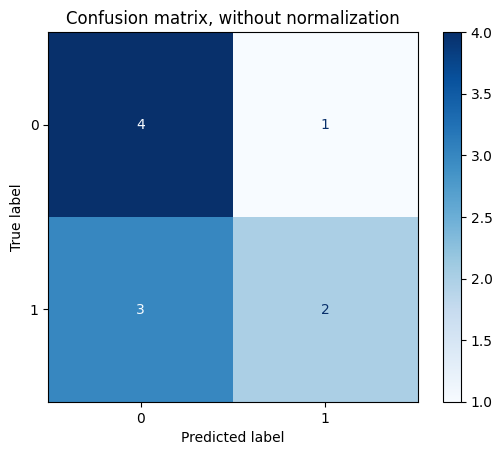

In [35]:
# confusion matrix using sklearn
# plot_confusion_matrix was removed in recent sklearn; use ConfusionMatrixDisplay instead

from sklearn.metrics import ConfusionMatrixDisplay

titles_options = [("Confusion matrix, without normalization", None)]

for title, normalize in titles_options:
    disp = ConfusionMatrixDisplay.from_estimator(lgrm, test_popDensity, test_detect,
                                                 display_labels=['0','1'],
                                                 cmap=plt.cm.Blues,
                                                 normalize=normalize)
    disp.ax_.set_title(title)

    print(title)
    print(disp.confusion_matrix)

plt.show()

## ROC

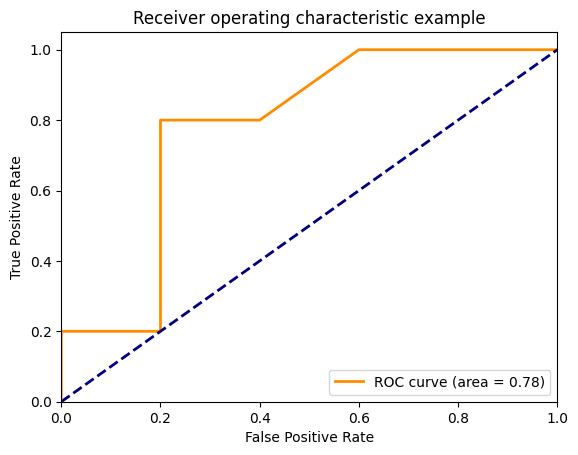

In [36]:
scores = y_detect_predict_prob[:,1]

fpr, tpr, thresholds = metrics.roc_curve(test_detect, scores, pos_label=1)

roc_auc = metrics.auc(fpr, tpr)

plt.figure()
lw = 2
plt.plot(fpr, tpr, color='darkorange',
         lw=lw, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic example')
plt.legend(loc="lower right")
plt.show()